# DESI DR2 LRG: covariance of two overlapping redshift bins against GLAM-Uchuu mocks

This notebook summarizes the validation of the multi-sample covariance (`OVERLAPPING_REDSHIFT_BINS.md`) on
DESI data: the joint covariance of the correlation functions of two overlapping LRG redshift bins,
**A: 0.40 < z < 0.55** and **B: 0.45 < z < 0.60** (NGC, pre-reconstruction), compared with the sample covariance of
350 GLAM-Uchuu altmtl mocks. The numbers here are the ones quoted in `BENCHMARK.md`, section 6.

**Set-up.** The two bins are two `Sample`s of one `Catalog`: the 0.4 < z < 0.6 random set of mock 150 (3.0e6 randoms
drawn from 4 random files, `n_data` = 694 911 galaxies; bin A holds 480 667 of them, bin B 558 236, and the shared
range 0.45 < z < 0.55 about two thirds of each bin). Pair counts come from pycorr (cucount on GPUs, Corrfunc on CPUs),
1 Mpc/h x 200 mu bins; the sample covariance uses Landy-Szalay with the **same 2 random files for DR and RR** (a first
version with 10 files for DR and 2 for RR produced spurious large-scale variance; see the investigation section). The covariance is computed in 30 bins of
4 Mpc/h from 40 to 160 Mpc/h, 100 mu bins, multipoles 0, 2, 4, for the three correlations AA, AB, BB (270 x 270).
The xi tables (2 Mpc/h x 10 mu bins, to 250 Mpc/h) are averaged over 5 mocks and the RR counts taken from mock 150.
The run used 256 loops (16 per subsample), N2, N3, N4 = 5, 10, 20, 7.7e11 draws, 72 minutes on 4 A100-40GB.
The 350-mock sample covariance covers the (AA, BB) data vector that enters a BAO fit; AB was not measured on the
sample set. The shot-noise rescaling is fitted to the mock covariance, because the mock counts carry no jackknives.

**Scripts.** `scripts/desi_zbins_measure_mocks.py` (counts, cosmodesi environment), `scripts/desi_zbins_prepare.py`
(sample set, xi tables, RR; cosmodesi environment), `scripts/desi_zbins_run.py` (RascalJax run and the printed
comparison; DESI-MG environment). This notebook only reads their outputs.

In [1]:
import os, sys
os.environ.setdefault("JAX_PLATFORMS", "cpu")  # nothing here needs a GPU
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
import pandas as pd
from scipy import stats
try:
    import rascaljax as rj
except ImportError:
    sys.path.insert(0, os.path.abspath(".."))
    import rascaljax as rj
from rascaljax.postprocess import (compare_covariances, check_eigval_convergence, check_positive_definite,
                                   convergence_check_extra, compute_D_precision_matrix, compute_N_eff)

BASE = "/pscratch/sd/w/willlake/rascaljax/desi_zbins_LRG_z0.4-0.55_z0.45-0.6"
D = f"{BASE}/NGC"           # final configuration: every input measured with the same 2 random files for DR and RR (see the investigation section)
D0 = f"{BASE}/NGC_first"    # first comparison: DR with 10 random files, RR with 2
OUT = f"{D}/rascaljax"
raw = rj.RawCovariance.load(f"{OUT}/Raw_Covariance.npz")
res = {tag: np.load(f"{OUT}/Rescaled_Covariance_{tag}.npz") for tag in ("alpha1", "alphaAA", "mockfit")}
cmp = np.load(f"{OUT}/comparison.npz")
mocks = np.load(f"{D}/mock_xi.npz")

b = raw.binning
n_s, n_ell, n_out = b.n_s, b.n_ell, b.n_out
names = ["AA", "AB", "BB"]
n_mock = int(cmp["n_mock"])
info = raw.info
alpha_aa = float(res["alphaAA"]["shot_noise_rescaling"][0])
alpha_j = float(res["mockfit"]["shot_noise_rescaling"][0])
print(f"covariance bins: {n_s} s bins from {b.s_edges[0]:g} to {b.s_edges[-1]:g} Mpc/h, multipoles {[int(l) for l in b.ells]}, "
      f"{len(names)} correlations -> {3 * n_out} x {3 * n_out} in (correlation, s, ell) order")
print(f"run: {info.get('n_loops')} loops, {info.get('loops_per_sample')} per subsample, N2 N3 N4 = {info.get('N2')} {info.get('N3')} {info.get('N4')}, "
      f"{info.get('runtime', 0) / 60:.0f} min")
print(f"RR check (Monte Carlo estimate / input counts, median over bins) for AA, AB, BB: {np.round(info.get('rr_check'), 4)}")
print(f"shot-noise rescaling: fit on the AA block = {alpha_aa:.4f}, fit on AA and BB jointly = {alpha_j:.4f}")
print(f"mocks: {n_mock} with correlations {[str(c) for c in mocks['correlations']]}")

covariance bins: 30 s bins from 40 to 160 Mpc/h, multipoles [0, 2, 4], 3 correlations -> 270 x 270 in (correlation, s, ell) order
run: 256 loops, 16 per subsample, N2 N3 N4 = 5 10 20, 75 min
RR check (Monte Carlo estimate / input counts, median over bins) for AA, AB, BB: [0.9991 0.9988 0.9997]
shot-noise rescaling: fit on the AA block = 1.2292, fit on AA and BB jointly = 1.2158
mocks: 350 with correlations ['AA', 'BB']


In [2]:
# ----- helpers: blocks of the joint matrices and the mock multipoles -----
def block(c, i, j):
    return c[i * n_out:(i + 1) * n_out, j * n_out:(j + 1) * n_out]

def bins(corrs, ells, s_sel, ell_major=False):
    # indices of a sub-vector in the (correlation, s, ell) ordering; ell_major reorders it to (correlation, ell, s) for display
    s_sel, ells = np.asarray(s_sel), np.asarray(ells)
    if ell_major:
        k = [ci * n_out + s_sel * n_ell + l for ci in corrs for l in ells]
    else:
        k = [ci * n_out + (s_sel[:, None] * n_ell + ells[None, :]).ravel() for ci in corrs]
    return np.concatenate(k)

def sub(c, k):
    return c[..., k[:, None], k[None, :]]

s_mid = b.s_mid
i_all = np.arange(n_s)
i_bao = np.flatnonzero((b.s_edges[:-1] >= 48) & (b.s_edges[1:] <= 152))   # the BAO fitting range
k_bao = bins((0, 2), (0, 1), i_bao)                                         # (AA, BB), ell = 0, 2, 48-152 Mpc/h
mock = cmp["mock"]                                                          # NaN in the AB blocks (not measured)
covs = {"alpha = 1": cmp["cov_alpha1"], f"alpha = {alpha_aa:.3f}": cmp["cov_alphaAA"]}
cov = cmp["cov_alphaAA"]

# mock multipoles: (correlation, mock, s, ell), same projection as the sample covariance
xis = mocks["xi_samples"]
v_mock = (xis.reshape(xis.shape[0], n_mock, -1) @ b.projection_matrix()).reshape(xis.shape[0], n_mock, n_s, n_ell)
print(f"(AA, BB) BAO data vector: {len(k_bao)} bins; mock multipoles {v_mock.shape}")

(AA, BB) BAO data vector: 104 bins; mock multipoles (2, 350, 30, 3)


## The data vectors

Mean multipoles of the 350 mocks in the two bins, with the mock scatter (error bars) and the RascalJax standard
deviation (bands, rescaling fitted on the AA block). The two bins share two thirds of their galaxies, so the two
curves are close and strongly correlated.

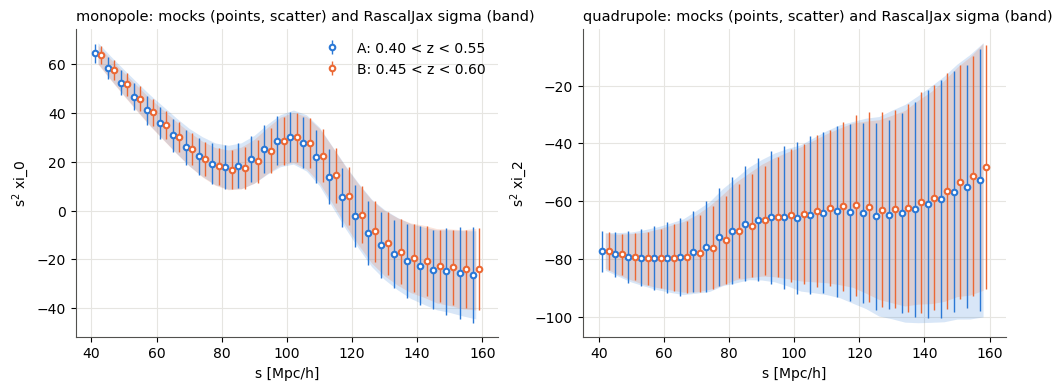

In [3]:
BLUE, ORANGE, GRAY, INK = "#2a78d6", "#eb6834", "#e6e5e1", "#52514e"
plt.rcParams.update({"font.size": 10, "axes.edgecolor": INK, "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.color": GRAY, "axes.axisbelow": True, "legend.frameon": False})

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, l, lab in zip(axes, (0, 1), ("monopole", "quadrupole")):
    for ci, mi, col, name in ((0, 0, BLUE, "A: 0.40 < z < 0.55"), (2, 1, ORANGE, "B: 0.45 < z < 0.60")):
        mean, std = v_mock[mi, :, :, l].mean(axis=0), v_mock[mi, :, :, l].std(axis=0, ddof=1)
        sig = np.sqrt(np.diag(block(cov, ci, ci))[l::n_ell])
        off = -1.0 if ci == 0 else 1.0
        ax.fill_between(s_mid, s_mid**2 * (mean - sig), s_mid**2 * (mean + sig), color=col, alpha=0.18, lw=0)
        ax.errorbar(s_mid + off, s_mid**2 * mean, s_mid**2 * std, fmt="o", ms=4, color=col, mfc="white", mew=1.5, lw=1, label=name)
    ax.set_xlabel("s [Mpc/h]"); ax.set_ylabel(f"s$^2$ xi_{2 * l}"); ax.set_title(f"{lab}: mocks (points, scatter) and RascalJax sigma (band)", loc="left", fontsize=10.5)
axes[0].legend(loc="upper right")
plt.show()

## Variance ratios and the correlation between the bins

Left and middle: diagonal of the RascalJax covariance over the mock covariance, monopole and quadrupole, for each
bin. The gray band is the scatter expected from 350 mocks alone, sqrt(2 / (N - 1)) = 0.08. Right: the correlation
coefficient between xi_A and xi_B in the same s bin, the quantity that only a joint calculation gives. The mock
points carry (1 - r^2) / sqrt(N) error bars.

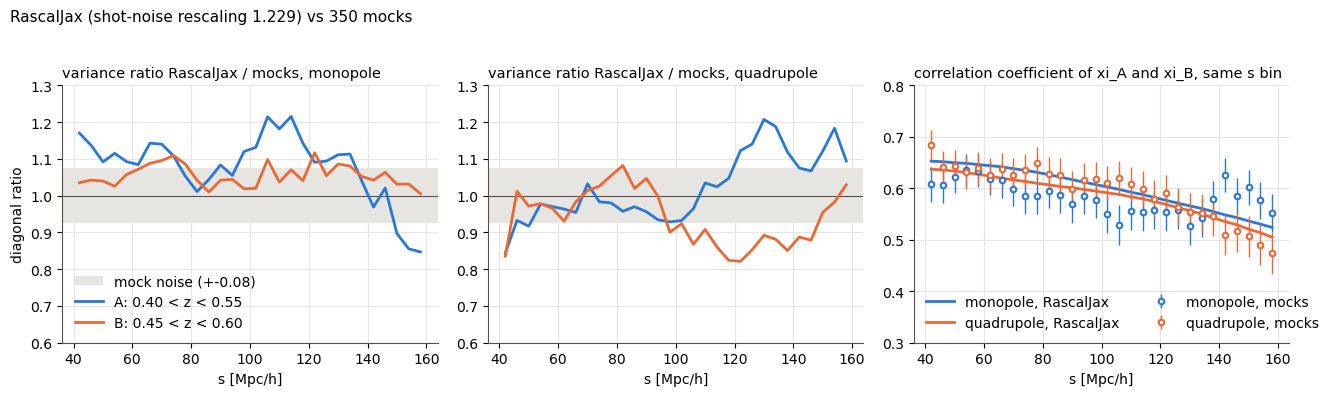

In [4]:
def diag_ell(c, ci, l):
    return np.diag(block(c, ci, ci))[l::n_ell]

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
band = np.sqrt(2 / (n_mock - 1))
for ax, l, lab in zip(axes[:2], (0, 1), ("monopole", "quadrupole")):
    ax.axhspan(1 - band, 1 + band, color=GRAY, lw=0, label=f"mock noise (+-{band:.2f})")
    ax.axhline(1, color=INK, lw=0.8)
    for ci, col, name in ((0, BLUE, "A: 0.40 < z < 0.55"), (2, ORANGE, "B: 0.45 < z < 0.60")):
        ax.plot(s_mid, diag_ell(cov, ci, l) / diag_ell(mock, ci, l), color=col, lw=2, label=name)
    ax.set_title(f"variance ratio RascalJax / mocks, {lab}", loc="left", fontsize=10.5); ax.set_ylim(0.6, 1.3); ax.set_xlabel("s [Mpc/h]")
axes[0].set_ylabel("diagonal ratio"); axes[0].legend(loc="lower left")
ax = axes[2]
for l, col, lab in ((0, BLUE, "monopole"), (1, ORANGE, "quadrupole")):
    cross_rj = np.diag(block(cov, 0, 2))[l::n_ell] / np.sqrt(diag_ell(cov, 0, l) * diag_ell(cov, 2, l))
    cross_mk = np.diag(block(mock, 0, 2))[l::n_ell] / np.sqrt(diag_ell(mock, 0, l) * diag_ell(mock, 2, l))
    ax.plot(s_mid, cross_rj, color=col, lw=2, label=f"{lab}, RascalJax")
    ax.errorbar(s_mid, cross_mk, (1 - cross_mk**2) / np.sqrt(n_mock), fmt="o", ms=4, color=col, mfc="white", mew=1.5, lw=1, label=f"{lab}, mocks")
ax.set_title("correlation coefficient of xi_A and xi_B, same s bin", loc="left", fontsize=10.5); ax.set_ylim(0.3, 0.8); ax.set_xlabel("s [Mpc/h]")
ax.legend(loc="lower left", ncol=2)
fig.suptitle(f"RascalJax (shot-noise rescaling {alpha_aa:.3f}) vs {n_mock} mocks", x=0.01, ha="left", fontsize=11)
fig.tight_layout(rect=(0, 0, 1, 0.95)); plt.show()

## Correlation matrices of the (A, B) data vector

The BAO data vector: monopole and quadrupole of both bins on 48-152 Mpc/h (104 bins), displayed in
(bin, multipole, s) order so that the blocks are visible. The off-diagonal A-B blocks are the new ingredient of
the joint covariance; their diagonal is the correlation coefficient plotted above.

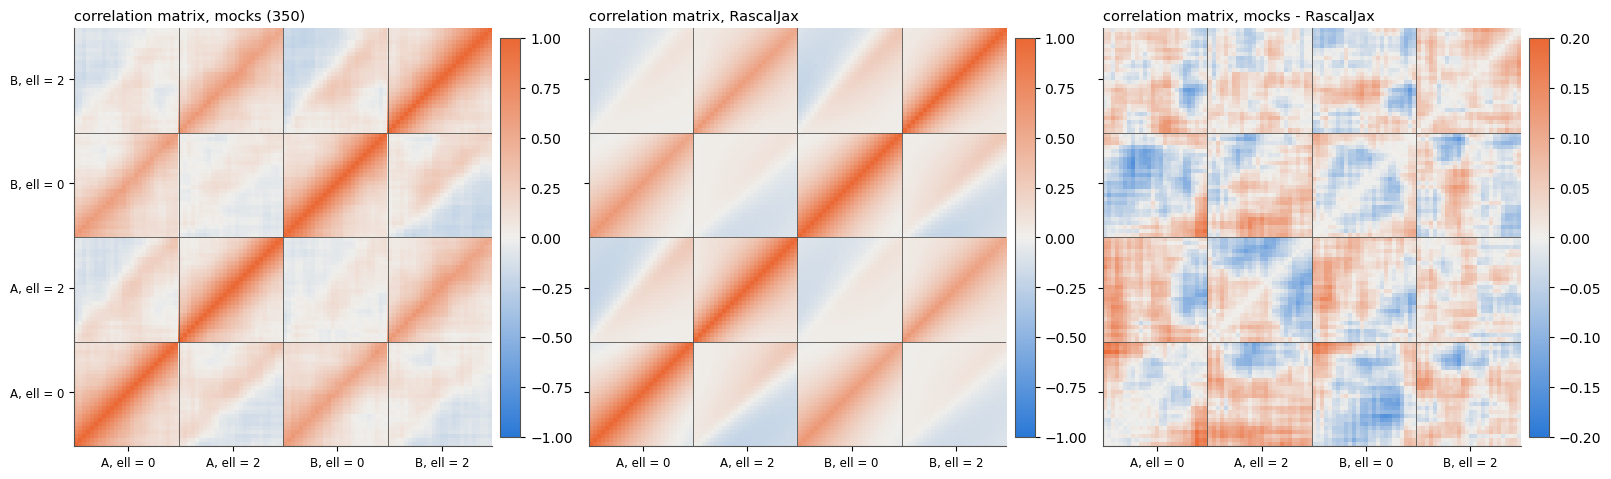

RMS difference of the off-diagonal correlation coefficients: 0.052 (noise of one coefficient from 350 mocks: ~0.053)


In [5]:
k_show = bins((0, 2), (0, 1), i_bao, ell_major=True)
n_blk = len(i_bao)
labels = ["A, ell = 0", "A, ell = 2", "B, ell = 0", "B, ell = 2"]
def corrmat(c):
    d = np.sqrt(np.diag(c)); return c / np.outer(d, d)
r_mock, r_rj = corrmat(sub(mock, k_show)), corrmat(sub(cov, k_show))
div = LinearSegmentedColormap.from_list("div", [BLUE, "#f0efec", ORANGE])
fig, axes = plt.subplots(1, 3, figsize=(16, 4.8), constrained_layout=True)
for ip, (ax, mat, title, lim) in enumerate(zip(axes, (r_mock, r_rj, r_mock - r_rj), (f"mocks ({n_mock})", "RascalJax", "mocks - RascalJax"), (1, 1, 0.2))):
    im = ax.imshow(mat, cmap=div, vmin=-lim, vmax=lim, origin="lower")
    for q in range(1, 4):
        ax.axhline(q * n_blk - 0.5, color=INK, lw=0.6); ax.axvline(q * n_blk - 0.5, color=INK, lw=0.6)
    ax.set_xticks(n_blk * (np.arange(4) + 0.5)); ax.set_xticklabels(labels, fontsize=8.5); ax.set_yticks(n_blk * (np.arange(4) + 0.5)); ax.set_yticklabels(labels if ip == 0 else [], fontsize=8.5)
    ax.grid(False); ax.set_title(f"correlation matrix, {title}", loc="left", fontsize=10.5); fig.colorbar(im, ax=ax, shrink=0.85, pad=0.02)
plt.show()
rms = np.sqrt(np.mean((r_mock - r_rj)[~np.eye(len(k_show), dtype=bool)] ** 2))
print(f"RMS difference of the off-diagonal correlation coefficients: {rms:.3f} (noise of one coefficient from {n_mock} mocks: ~{1 / np.sqrt(n_mock):.3f})")

## Comparison metrics

Metrics of Rashkovetskyi et al. (2023, 2025) between the mock covariance and the RascalJax covariance on the BAO
data vector: R_inv (RMS eigenvalue of C1^-1 C2 - 1), D_KL, and the reduced chi2 - 1, in both directions
(mock first, RascalJax first). The sample covariance of 350 mocks is itself noisy in 104 dimensions, so the
reference is not zero: the "expected if RascalJax were exact" row is the mean and scatter of the same metrics
between a Wishart-distributed sample covariance of 350 draws from the RascalJax covariance and the RascalJax
covariance (the +0.43 of the mock-first chi2 is the Hartlap bias of the inverted sample covariance).

The last rows are the test used by RascalC: the mean reduced chi2 of the mock data vectors around their mean with
the RascalJax precision matrix, which is 1 for a correct covariance. "all bins" uses all 30 s bins and all three
multipoles of a block as `desi_zbins_run.py` prints; "BAO" the 104-bin data vector.

In [6]:
rng = np.random.default_rng(1)
def metrics(c1, c2):
    r = compare_covariances(c1, c2, log=lambda *a: None)
    return [r["R_inv"][0], r["R_inv"][1], r["D_KL"][0], r["D_KL"][1], r["chi2_red-1"][0], r["chi2_red-1"][1]]
cols = ["R_inv (mock, RJ)", "R_inv (RJ, mock)", "D_KL (mock, RJ)", "D_KL (RJ, mock)", "chi2_red-1 (mock, RJ)", "chi2_red-1 (RJ, mock)"]
rows = {}
for lab, c in covs.items():
    rows[f"(A, B) BAO, {lab}"] = metrics(sub(mock, k_bao), sub(c, k_bao))
for ci, nm in ((0, "A"), (2, "B")):
    k = bins((ci,), (0, 1), i_bao)
    rows[f"{nm} alone, BAO, alpha = {alpha_aa:.3f}"] = metrics(sub(mock, k), sub(cov, k))
# expectation from the mock sampling noise alone, if the RascalJax covariance were the truth
truth = sub(cov, k_bao); L = np.linalg.cholesky(truth)
sim = np.array([metrics(np.cov((L @ rng.standard_normal((len(k_bao), n_mock)))), truth) for _ in range(100)])
rows[f"expected if RascalJax were exact ({n_mock} mocks, mean)"] = sim.mean(axis=0)
rows["  scatter of that expectation"] = sim.std(axis=0)
table = pd.DataFrame(rows, index=cols).T
pd.set_option("display.width", 200); display(table.round(3))

# mean reduced chi2 of the mocks with the RascalJax precision (the mean of the mocks is subtracted, hence N / (N - 1))
chi_rows = {}
for lab, c in covs.items():
    row = {}
    for sel, nm in (([0], "A"), ([1], "B"), ([0, 1], "A+B")):
        for rng_lab, s_sel, ells in (("all bins", i_all, np.arange(n_ell)), ("BAO", i_bao, np.array([0, 1]))):
            dv = np.concatenate([(v_mock[mi] - v_mock[mi].mean(axis=0))[:, s_sel][:, :, ells].reshape(n_mock, -1) for mi in sel], axis=1)
            k = bins([2 * mi for mi in sel], ells, s_sel)
            chi2 = np.einsum("ia,ab,ib->i", dv, np.linalg.inv(sub(c, k)), dv)
            row[f"{nm}, {rng_lab}"] = chi2.mean() / len(k) * n_mock / (n_mock - 1)
    chi_rows[f"mock reduced chi2, {lab}"] = row
display(pd.DataFrame(chi_rows).T.round(3))

,"R_inv (mock, RJ)","R_inv (RJ, mock)","D_KL (mock, RJ)","D_KL (RJ, mock)","chi2_red-1 (mock, RJ)","chi2_red-1 (RJ, mock)"
"(A, B) BAO, alpha = 1",0.804,0.740,10.950,10.467,0.167,0.245
"(A, B) BAO, alpha = 1.229",1.066,0.530,14.029,8.621,0.460,-0.025
"A alone, BAO, alpha = 1.229",0.527,0.380,2.532,2.022,0.188,-0.013
"B alone, BAO, alpha = 1.229",0.555,0.371,2.682,2.036,0.213,-0.032
"expected if RascalJax were exact (350 mocks, mean)",1.035,0.549,13.671,8.763,0.432,-0.001
scatter of that expectation,0.029,0.006,0.457,0.171,0.014,0.007


,"A, all bins","A, BAO","B, all bins","B, BAO","A+B, all bins","A+B, BAO"
"mock reduced chi2, alpha = 1",1.268,1.262,1.240,1.233,1.255,1.245
"mock reduced chi2, alpha = 1.229",0.989,0.987,0.971,0.968,0.980,0.975


## Convergence of the Monte Carlo integrals

RascalC's checks on the (A, B) BAO block: the eigenvalue test of the 4-point term against the 2-point term, positive
definiteness, the agreement between halves of the 16 subsamples and the effective number of samples N_eff. The
same checks on the matrix that includes the AB cross-correlation fail: with two thirds of each bin shared, xi_AB is
nearly a linear combination of xi_AA and xi_BB, so the joint 2-point term has a near-null direction (its smallest
eigenvalue is 50 times below that of the (A, B) block) that the 4-point sampling noise has not resolved at 256 loops.
That block is not part of a BAO fit of (A, B); using it would need many more loops.

In [7]:
z = res["alphaAA"]
c2, c4, full, part = z["c2_terms"][0], z["c4_term"], z["full_theory_covariance"], z["individual_theory_covariances"]
for k, lab in ((k_bao, "(A, B), ell = 0, 2, 48-152 Mpc/h"), (bins((0, 1, 2), (0, 1), i_all), "(AA, AB, BB), ell = 0, 2, 40-160 Mpc/h")):
    print(f"===== {lab}: {len(k)} bins")
    check_eigval_convergence(sub(c2, k), sub(c4, k), alpha=alpha_aa)
    pd_ok = check_positive_definite(sub(full, k))
    ev = np.linalg.eigvalsh(sub(full, k)); print(f"positive definite: {pd_ok}; eigenvalues {ev.min():.2e} .. {ev.max():.2e}")
    convergence_check_extra(sub(part, k))
    Dm, _ = compute_D_precision_matrix(sub(part, k), sub(full, k)); compute_N_eff(Dm)

===== (A, B), ell = 0, 2, 48-152 Mpc/h: 104 bins
convergence check: min eigenvalue of C2 = 5.54e-09, of C4 = -1.16e-08
convergence check: min eigenvalue of C2^-1/2 C4 C2^-1/2 = -0.121 (should be > -1.51)
positive definite: True; eigenvalues 1.14e-08 .. 1.17e-04
First half vs second half: R_inv = 6.99e-02, 6.89e-02; D_KL = 1.25e-01, 1.24e-01; chi2_red-1 = 4.49e-03, 2.91e-04
Even vs odd subsamples: R_inv = 6.91e-02, 7.05e-02; D_KL = 1.25e-01, 1.26e-01; chi2_red-1 = -1.87e-04, 5.01e-03
Effective number of samples N_eff = 1.7537e+05
===== (AA, AB, BB), ell = 0, 2, 40-160 Mpc/h: 180 bins
convergence check: min eigenvalue of C2 = 9.65e-11, of C4 = -3.56e-08
convergence check: min eigenvalue of C2^-1/2 C4 C2^-1/2 = -9.641 (should be > -1.51)
positive definite: False; eigenvalues -5.74e-10 .. 2.14e-04
First half vs second half: R_inv = 7.33e-01, 5.26e-01; D_KL = 3.11e+00, -1.17e+00; chi2_red-1 = 3.27e-02, -1.11e-02
Even vs odd subsamples: R_inv = 1.12e+00, 6.70e-01; D_KL = 6.41e+00, 2.64e-01; 

## Distribution of the mock chi2

chi2 of each mock's (A, B) BAO data vector around the mock mean, with the RascalJax precision matrix with and without
the shot-noise rescaling, against the chi2 distribution with 104 degrees of freedom (scaled by (N - 1) / N for the
subtracted mean). Without rescaling the covariance is 15% too small; with the single rescaling of the catalog it
describes both bins and their cross-covariance.

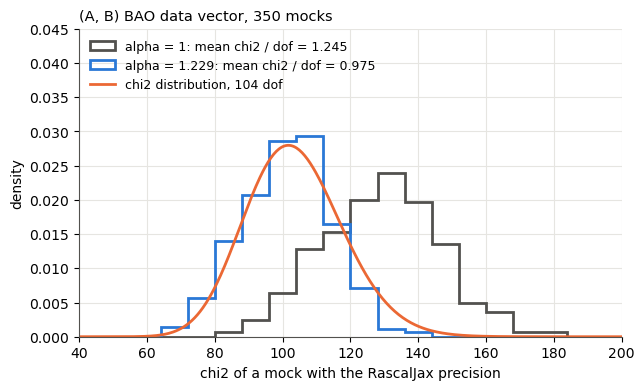

In [8]:
dv = np.concatenate([(v_mock[mi] - v_mock[mi].mean(axis=0))[:, i_bao][:, :, :2].reshape(n_mock, -1) for mi in (0, 1)], axis=1)
dof = len(k_bao); scale = (n_mock - 1) / n_mock
x = np.linspace(40, 200, 400)
fig, ax = plt.subplots(figsize=(7, 4))
for (lab, c), col in zip(covs.items(), (INK, BLUE)):
    chi2 = np.einsum("ia,ab,ib->i", dv, np.linalg.inv(sub(c, k_bao)), dv)
    ax.hist(chi2, bins=np.arange(40, 201, 8), histtype="step", lw=2, color=col, density=True, label=f"{lab}: mean chi2 / dof = {chi2.mean() / dof / scale:.3f}")
ax.plot(x, stats.chi2.pdf(x / scale, dof) / scale, color=ORANGE, lw=2, label=f"chi2 distribution, {dof} dof")
ax.set_xlabel("chi2 of a mock with the RascalJax precision"); ax.set_ylabel("density"); ax.set_xlim(40, 200); ax.set_ylim(0, 0.045); ax.legend(loc="upper left", fontsize=9)
ax.set_title("(A, B) BAO data vector, 350 mocks", loc="left", fontsize=10.5); plt.show()

## Why the first comparison disagreed: random-catalog noise in the mock measurements

The first sample covariance was built from measurements that used 10 random files for DR but only 2 for RR (RR is the
expensive count). Against RascalJax it showed two significant anomalies: the monopole variance was 15-25% below the
model above 130 Mpc/h (3.0 sigma for bin A against the mock noise) and the monopole correlation coefficient between
the bins was 0.05-0.10 above the model (3.7 sigma), while the quadrupole and all transverse pairs agreed. Three
RascalJax runs with different xi tables (the three per-correlation 5-mock tables, one common table, and the 350-mock
mean table) gave identical results, which excluded the model side.

The cause is the estimator: Landy-Szalay cancels the edge noise of the random catalog (which random points fall near
the survey boundaries) only when DR and RR use the same randoms. With different sets the RR fluctuation enters xi
directly. On mock 150, two independent 2-file RR realizations differ by 3-6e-4 (relative) at s = 150 Mpc/h for
mu > 0.4 and by under 0.4e-4 for the most transverse pairs; in the monopole this is 0.13 of the mock scatter at 42 Mpc/h
and 0.3 at 100-140 Mpc/h, i.e. about 10% of the variance, coherent in s, concentrated in radial pairs near the redshift
edges, and independent between the two bins because their redshift edges differ: exactly the two anomalies.

The fix recomputes DR with the same 2 random files as RR and rebuilds Landy-Szalay from the stored DD and RR
(`desi_zbins_measure_mocks.py` now defaults to the same files for DR and RR); the xi tables and RR inputs were rebuilt
the same way and RascalJax rerun on them (the covariance changed by under 1%). The cells below compare the first and
the corrected mock covariances with the RascalJax covariance of the respective inputs; the "expected" scatter is the Wishart
expectation for 350 mocks if RascalJax were exact.

In [9]:
cmp0 = np.load(f"{D0}/rascaljax/comparison.npz"); mock0, cov0 = cmp0["mock"], cmp0["cov_alphaAA"]
def stats_of(C):
    dA, dB = np.diag(C)[bins((0,), (0,), i_all)], np.diag(C)[bins((2,), (0,), i_all)]
    r0 = np.diag(C[bins((0,), (0,), i_all)][:, bins((2,), (0,), i_all)]) / np.sqrt(dA * dB)
    return dA, dB, r0
hi, lo = s_mid > 130, s_mid < 120
def summary(C_mock, C_rj):
    dA_m, dB_m, r0_m = stats_of(C_mock); dA_r, dB_r, r0_r = stats_of(C_rj)
    return np.array([np.mean(r0_r - r0_m), np.mean((dA_r / dA_m)[hi]), np.mean((dB_r / dB_m)[hi]), np.mean((dA_r / dA_m)[lo]), np.mean((dB_r / dB_m)[lo])])
names_st = ["mean r_AB offset (model - mock), ell=0", "var ratio A, s > 130", "var ratio B, s > 130", "var ratio A, s < 120", "var ratio B, s < 120"]
# Wishart expectation of the same statistics (sample covariance of 350 draws from the RascalJax covariance)
kk = bins((0, 2), (0, 1, 2), i_all); L = np.linalg.cholesky(cov[kk[:, None], kk[None, :]]); rng = np.random.default_rng(3); full = np.full_like(cov, np.nan); sims = []
for _ in range(200):
    full[kk[:, None], kk[None, :]] = np.cov(L @ rng.standard_normal((len(kk), n_mock))); sims.append(summary(full, cov))
sims = np.array(sims)
tab = pd.DataFrame({"first measurement (DR 10 files, RR 2)": summary(mock0, cov0), "consistent measurement (same 2 files)": summary(mock, cov),
                    "expected if RascalJax exact": sims.mean(axis=0), "scatter": sims.std(axis=0)}, index=names_st)
tab["significance, first"] = (tab.iloc[:, 0] - tab.iloc[:, 2]) / tab.iloc[:, 3]; tab["significance, consistent"] = (tab.iloc[:, 1] - tab.iloc[:, 2]) / tab.iloc[:, 3]
display(tab.round(3))

,"first measurement (DR 10 files, RR 2)",consistent measurement (same 2 files),expected if RascalJax exact,scatter,"significance, first","significance, consistent"
"mean r_AB offset (model - mock), ell=0",0.063,0.017,0.000,0.017,3.617,0.998
"var ratio A, s > 130",0.827,0.963,1.004,0.061,-2.904,-0.665
"var ratio B, s > 130",0.897,1.044,1.005,0.066,-1.641,0.598
"var ratio A, s < 120",1.053,1.117,1.000,0.047,1.139,2.509
"var ratio B, s < 120",1.011,1.054,1.008,0.046,0.063,0.993


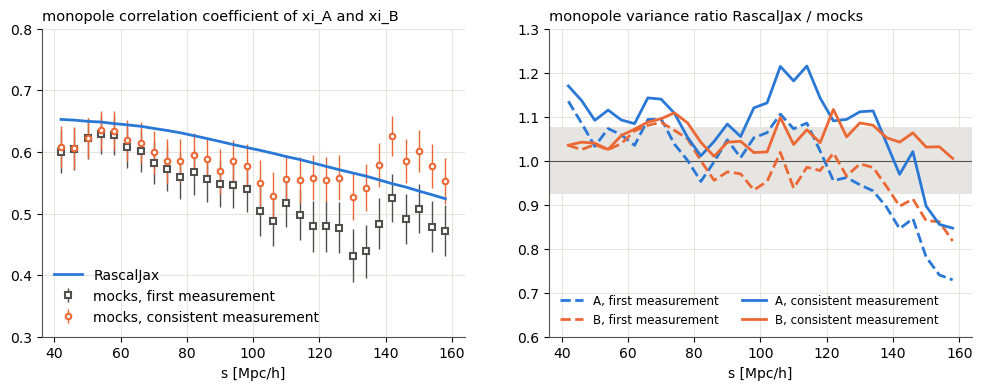

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ax = axes[0]
for C, col, lab, mk in ((mock0, INK, "mocks, first measurement", "s"), (mock, ORANGE, "mocks, consistent measurement", "o")):
    _, _, r0 = stats_of(C); ax.errorbar(s_mid, r0, (1 - r0**2) / np.sqrt(n_mock), fmt=mk, ms=4, color=col, mfc="white", mew=1.5, lw=1, label=lab)
ax.plot(s_mid, stats_of(cov)[2], color=BLUE, lw=2, label="RascalJax"); ax.set_ylim(0.3, 0.8); ax.set_xlabel("s [Mpc/h]")
ax.set_title("monopole correlation coefficient of xi_A and xi_B", loc="left", fontsize=10.5); ax.legend(loc="lower left")
ax = axes[1]; band = np.sqrt(2 / (n_mock - 1)); ax.axhspan(1 - band, 1 + band, color=GRAY, lw=0); ax.axhline(1, color=INK, lw=0.8)
for C, Cr, ls, lab in ((mock0, cov0, "--", "first measurement"), (mock, cov, "-", "consistent measurement")):
    dA_m, dB_m, _ = stats_of(C); dA_r, dB_r, _ = stats_of(Cr)
    ax.plot(s_mid, dA_r / dA_m, color=BLUE, lw=2, ls=ls, label=f"A, {lab}"); ax.plot(s_mid, dB_r / dB_m, color=ORANGE, lw=2, ls=ls, label=f"B, {lab}")
ax.set_ylim(0.6, 1.3); ax.set_xlabel("s [Mpc/h]"); ax.set_title("monopole variance ratio RascalJax / mocks", loc="left", fontsize=10.5); ax.legend(loc="lower left", ncol=2, fontsize=8.5)
plt.show()

## Summary

- **The RR normalization is right on real data.** The Monte Carlo estimate of the RR counts reproduces the
  sample-normalized pycorr counts, after conversion to the catalog normalization, to 0.1% in all three correlations.
- **One shot-noise rescaling per catalog serves both bins.** Fitted on the AA block alone (1.229), it gives a mock
  reduced chi2 of 0.99 for A, 0.97 for B and 0.98 jointly; the joint fit on A and B gives nearly the same value (1.216).
  The value is above 1 partly because the Landy-Szalay random-noise term with only 2 random files (of order N_D/N_R =
  1/11 of the shot-noise part) is in the mocks' variance and is absorbed by the rescaling.
- **The covariance of the (A, B) data vector agrees with the 350 mocks to the mock noise.** R_inv, D_KL and the
  reduced chi2 of the mock-vs-RascalJax comparison (1.07, 14.0, +0.46 mock-first; 0.53, 8.6, -0.025 RascalJax-first)
  are close to what a 350-mock sample covariance of the RascalJax covariance itself would give
  (1.04 +- 0.03, 13.7 +- 0.5, +0.43 +- 0.01; 0.55 +- 0.01, 8.8 +- 0.2, 0.00 +- 0.01); the RascalJax covariance is 2%
  too large in the chi2 metric.
- **The cross-covariance of the bins, the new ingredient, is right.** The correlation coefficient between xi_A and
  xi_B agrees with the mocks at every separation and direction (mean monopole offset 0.017, 1.0 sigma of the mock noise).
- **Remaining differences are at the usual RascalC level:** the monopole variance of bin A is 12% above the mocks
  below 120 Mpc/h (2.4 sigma) and the quadrupole of bin B 10-15% below on 100-140 Mpc/h; above 130 Mpc/h the monopole
  agrees (bin A 0.96 +- 0.06, bin B 1.04 +- 0.06).
- **A first comparison showed two spurious anomalies** (monopole variance 15-25% low above 130 Mpc/h, cross-bin
  correlation 0.05-0.10 high) that came from the mock measurement, not from RascalJax: RR counts from 2 random files
  against DR from 10 break the Landy-Szalay cancellation of the random-catalog edge noise. See the investigation
  section. A fully clean sample covariance would use 4 or more identical random files for DD, DR and RR.
- **The AB-inclusive matrix is not converged** at 256 loops because of its near-null direction; it is not needed
  for a BAO fit of the two bins.